# Real-Time Retail Intelligence Platform — ML notebook

This notebook is the **analysis companion** to the app. It reads the MongoDB aggregation outputs the three models are trained on, and shows how each model was chosen and how well it works. **It only reads**: nothing here writes to the database.

| Model | Reads (MongoDB aggregation output) | Produces |
|---|---|---|
| Module 1 — K-Means | `rfm_features` (Pipeline A: `$group` + `$lookup`) | `customers.segment` |
| Module 2 — Collaborative filtering | `category_affinity` (Pipeline B: `$unwind` + `$group`) | `category_similarity` |
| Module 3 — Isolation Forest | `rolling_behavioral_metrics` (Pipeline C: `$setWindowFields`) | `customers.anomaly` |

**Data provenance.** `customers`, `orders`, `products` and `reviews` are the REAL Olist Brazilian e-commerce dataset (2016–2018). `events` are SYNTHETIC, generated by `simulator/event_simulator.py` and labelled `metadata.is_synthetic: true`, plus events from people using the app (`metadata.source: "app"`). Olist has no clickstream data, so nothing behavioural here is claimed to be real.

Run it after `python ml/run_all.py`, from the `retail-intelligence-platform/` folder, with MongoDB running.

In [1]:
%matplotlib inline
import os, sys
sys.path.insert(0, os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from config import get_db
from ml import module1_kmeans as m1, module2_collaborative_filtering as m2, module3_isolation_forest as m3

plt.rcParams.update({'figure.figsize': (7, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
db = get_db()
pd.DataFrame([(c, db[c].estimated_document_count()) for c in
              ['customers', 'orders', 'products', 'reviews', 'events', 'rfm_features',
               'category_affinity', 'rolling_behavioral_metrics', 'category_similarity']],
             columns=['collection', 'documents']).set_index('collection')

,documents
collection,
customers,96098
orders,99444
products,32951
reviews,102230
events,25702
rfm_features,94401
category_affinity,96856
rolling_behavioral_metrics,25633
category_similarity,74


## 1. Exploring the RFM features (Pipeline A output)

Olist issues a new `customer_id` for every order. The loader keys customers on `customer_unique_id` (the real person), which is what makes **Frequency** meaningful. Even so, most people buy once, so Frequency and Monetary are heavily skewed.

94,401 customers with at least one completed order
frequency      1     2    3   4  5  6  7  9
customers  91539  2630  184  29  9  5  3  1


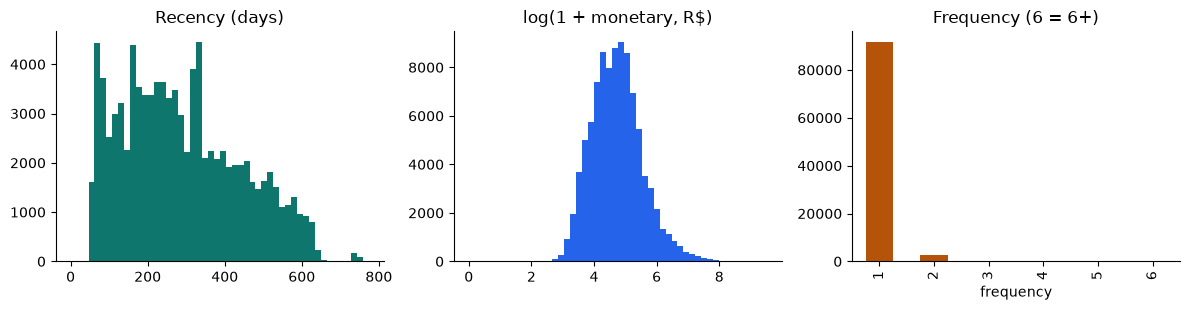

In [2]:
rfm = m1.load_rfm(db)
print(f"{len(rfm):,} customers with at least one completed order")
print(rfm['frequency'].value_counts().sort_index().head(8).rename('customers').to_frame().T.to_string())
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].hist(rfm['recency_days'], bins=50, color='#0f766e'); ax[0].set_title('Recency (days)')
ax[1].hist(np.log1p(rfm['monetary']), bins=50, color='#2563eb'); ax[1].set_title('log(1 + monetary, R$)')
rfm['frequency'].clip(upper=6).value_counts().sort_index().plot.bar(ax=ax[2], color='#b45309'); ax[2].set_title('Frequency (6 = 6+)')
plt.tight_layout()

## 2. Module 1 — choosing k for K-Means

Frequency and Monetary are `log1p`-transformed, then all three features are standardised. Silhouette is computed on a 10,000-customer sample, because it is O(n²). The app needs at least 4 actionable segments, so k is chosen from 4–6. The plot also shows k = 2–3 for reference.

,inertia,silhouette
k,,
2,192312.928,0.703
3,127690.822,0.361
4,86727.258,0.370
5,71181.126,0.358
6,59996.231,0.348
7,51336.568,0.359
8,45711.021,0.349


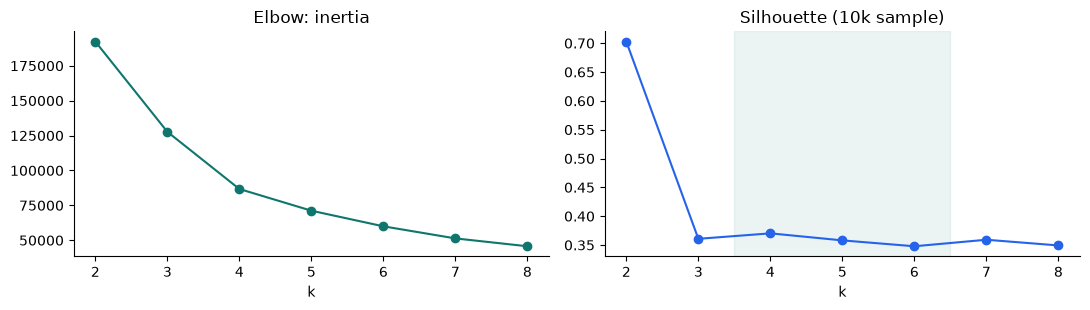

In [3]:
X = StandardScaler().fit_transform(m1.transform(rfm))
rng = np.random.default_rng(42); idx = rng.choice(len(X), size=min(10_000, len(X)), replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    rows.append((k, km.inertia_, silhouette_score(X[idx], km.labels_[idx])))
scores = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette']).set_index('k')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
scores['inertia'].plot(ax=ax[0], marker='o', color='#0f766e', title='Elbow: inertia')
scores['silhouette'].plot(ax=ax[1], marker='o', color='#2563eb', title='Silhouette (10k sample)')
ax[1].axvspan(3.5, 6.5, color='#0f766e', alpha=0.08)
plt.tight_layout(); scores.round(3)

In [4]:
bundle = m1.load_model()
seg = pd.DataFrame(list(db.customers.aggregate([
    {'$match': {'segment.method': {'$in': ['kmeans', 'kmeans-live']}}},
    {'$lookup': {'from': 'rfm_features', 'localField': '_id', 'foreignField': '_id', 'as': 'r'}}, {'$unwind': '$r'},
    {'$project': {'_id': 0, 'segment': '$segment.label', 'recency_days': '$r.recency_days',
                  'frequency': '$r.frequency', 'monetary': '$r.monetary'}}])))
print(f"Saved model: k = {bundle['k']}, silhouette by k = { {k: round(v, 3) for k, v in bundle['silhouettes'].items()} }")
profile = seg.groupby('segment').agg(customers=('segment', 'size'), recency_days=('recency_days', 'mean'),
                                     frequency=('frequency', 'mean'), monetary=('monetary', 'mean')).round(1)
profile['share'] = (100 * profile['customers'] / profile['customers'].sum()).round(1).astype(str) + '%'
profile.sort_values('monetary', ascending=False)

Saved model: k = 4, silhouette by k = {4: 0.369, 5: 0.35, 6: 0.342}


,customers,recency_days,frequency,monetary,share
segment,,,,,
Big Spender,27973,224.4,1.0,320.0,29.6%
High-Value Loyal,2862,270.5,2.1,307.3,3.0%
At-Risk,27252,475.6,1.0,119.0,28.9%
Bargain Browser,36314,197.2,1.0,69.6,38.5%


**Reading the segments.** Names come from deterministic rules on the centroids, not by hand:
- the cluster with the highest mean frequency is *High-Value Loyal* (the repeat buyers);
- of the rest, the longest time since the last order is *At-Risk*;
- the lowest spend is *Bargain Browser*;
- the highest spend is *Big Spender*.

Each segment drives a different offer in the store (free shipping, 15% win-back, and so on). A sign-up with no completed order is labelled *New Customer* by rule until K-Means can place them.

## 3. Module 2 — recommendations: does collaborative filtering beat popularity?

**Protocol.** Take customers who bought from 2+ categories and split them by customer into test (20%), validation (20%) and train. Item-item cosine similarities and popularity are computed on train only. For each held-out customer, hide one category they bought, recommend from the rest, and check whether the hidden category is in the top 3 or top 5 (HitRate@k). Three rankers are compared:
- pure CF;
- a CF + popularity blend, with the blend weight α chosen on validation;
- a popularity-only baseline.

train 93,484 · validation 458 · test 458 customers; chosen alpha = 1.0


,hit_rate@3,hit_rate@5
CF only,0.2467,0.3581
CF + popularity (alpha=1.0),0.3057,0.4127
Popularity baseline,0.1987,0.3930


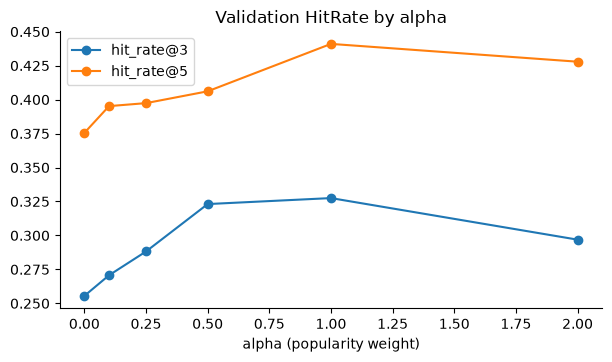

In [5]:
aff = m2.load_affinity_frame(db)
ev = m2.evaluate(aff)
print(f"train {ev['train_customers']:,} · validation {ev['validation_customers']} · test {ev['test_customers']} customers; chosen alpha = {ev['alpha']}")
val = pd.DataFrame(ev['validation_by_alpha']).T; val.index = val.index.astype(float)
fig, ax = plt.subplots()
val.plot(ax=ax, marker='o'); ax.set_xlabel('alpha (popularity weight)'); ax.set_title('Validation HitRate by alpha')
pd.DataFrame(ev['test']).T.rename(index={'collaborative_filtering': 'CF only', 'hybrid': f"CF + popularity (alpha={ev['alpha']})",
                                         'popularity_baseline': 'Popularity baseline'})

In [6]:
sim, popular, alpha = m2.load_saved_model(db)
examples = aff.groupby('customer_id').filter(lambda g: len(g) >= 2)['customer_id'].drop_duplicates().head(4)
rows = []
for cid in examples:
    spend = dict(aff[aff.customer_id == cid][['category', 'spend']].values)
    for r in m2.recommend_categories(spend, sim, popular, 3, alpha):
        rows.append({'customer': cid[:14] + '…', 'bought': ', '.join(spend), 'recommended': r['category'],
                     'because': r['because'] or r['reason']})
pd.DataFrame(rows)

,customer,bought,recommended,because
0,c_edb73fb9e9c6…,"toys, furniture_decor",bed_bath_table,furniture_decor
1,c_edb73fb9e9c6…,"toys, furniture_decor",housewares,furniture_decor
2,c_edb73fb9e9c6…,"toys, furniture_decor",sports_leisure,toys
3,c_9e7aef9f78fa…,"bed_bath_table, furniture_bedroom",furniture_decor,bed_bath_table
4,c_9e7aef9f78fa…,"bed_bath_table, furniture_bedroom",health_beauty,bed_bath_table
5,c_9e7aef9f78fa…,"bed_bath_table, furniture_bedroom",home_confort,bed_bath_table
6,c_ca26c28cab4d…,"perfumery, telephony",health_beauty,perfumery
7,c_ca26c28cab4d…,"perfumery, telephony",sports_leisure,perfumery
8,c_ca26c28cab4d…,"perfumery, telephony",bed_bath_table,perfumery
9,c_b59e4bb4efe8…,"furniture_decor, art, christmas_supplies",bed_bath_table,furniture_decor


**Interpretation.** About 97% of Olist customers order once, so the co-purchase signal is thin. Pure CF alone is weak, and popularity is a strong baseline. Blending the two beats both on held-out customers. The store uses the blended ranker, and every recommendation stays explainable ("because you shop in X").

## 4. Module 3 — behavioural anomalies (Isolation Forest on `$setWindowFields` features)

Features per customer come from the latest row of `rolling_behavioral_metrics`:
- events in the last 7 days (a RANGE window);
- average gap over the last 10 events and the abandonment share (DOCUMENTS windows).

The count and the gap are `log1p`-scaled. Scores are bucketed by percentile: the bottom 10% are HIGH and the next 20% MEDIUM.

**Evaluation with known labels.** The event simulator gives ~3% of simulated customers an "intense" persona: ~2 s between clicks and frequent abandonment. Because it is synthetic, the label is known, so we can measure recall and precision. The persona is never a model feature.

,rolling_event_count_7d,avg_session_gap_seconds,cart_to_purchase_trend,cart_abandon_trend,customers
risk,,,,,
HIGH,15.24,53091.78,0.14,0.10,147
LOW,12.02,54992.82,0.05,0.12,1025
MEDIUM,12.28,57054.23,0.08,0.09,293


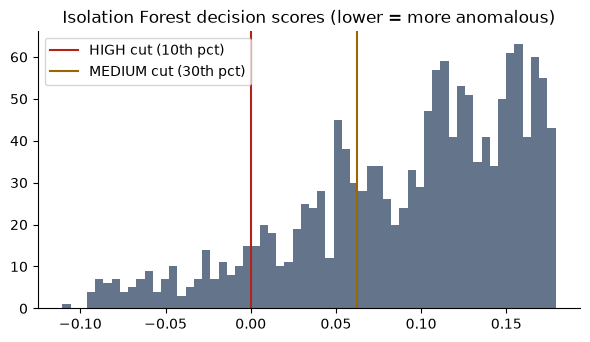

In [7]:
metrics = m3.load_latest_metrics_per_customer(db)
model = m3.load_model()
Xa = m3.model_matrix(metrics, model['fills'])
metrics['score'] = model['model'].decision_function(Xa)
metrics['risk'] = metrics['score'].apply(lambda s: m3.risk_label_from_score(s, model['high_cut'], model['medium_cut']))
fig, ax = plt.subplots()
ax.hist(metrics['score'], bins=60, color='#64748b')
ax.axvline(model['high_cut'], color='#b42318', label='HIGH cut (10th pct)'); ax.axvline(model['medium_cut'], color='#9a6700', label='MEDIUM cut (30th pct)')
ax.set_title('Isolation Forest decision scores (lower = more anomalous)'); ax.legend()
metrics.groupby('risk')[m3.FEATURES].mean().round(2).assign(customers=metrics['risk'].value_counts())

In [8]:
personas = {d['_id']: d['persona'] for d in db.events.aggregate([
    {'$match': {'metadata.source': 'simulator'}}, {'$group': {'_id': '$customer_id', 'persona': {'$first': '$metadata.persona'}}}])}
sim_c = metrics[metrics.customer_id.isin(personas)].copy()
sim_c['intense'] = sim_c.customer_id.map(personas).eq('intense')
pd.crosstab(sim_c['intense'].map({True: 'intense persona', False: 'normal'}), sim_c['risk'], margins=True)

risk,HIGH,LOW,MEDIUM,All
intense,,,,
intense persona,17,1,1,19
normal,129,1024,292,1445
All,146,1025,293,1464


In [9]:
tp = (sim_c.intense & sim_c.risk.eq('HIGH')).sum()
print(f"Recall of the intense persona at HIGH: {tp}/{sim_c.intense.sum()} = {tp / sim_c.intense.sum():.0%}")
print(f"Recall at HIGH or MEDIUM: {(sim_c.intense & sim_c.risk.isin(['HIGH', 'MEDIUM'])).sum() / sim_c.intense.sum():.0%}")
print(f"Precision of HIGH: {tp}/{sim_c.risk.eq('HIGH').sum()} — capped by design, since HIGH is always 10% of customers and only ~1-3% are intense")

Recall of the intense persona at HIGH: 17/19 = 89%
Recall at HIGH or MEDIUM: 95%
Precision of HIGH: 17/146 — capped by design, since HIGH is always 10% of customers and only ~1-3% are intense


## 5. Conclusions

- **Traceability.** Each model is trained only on a MongoDB aggregation output (`rfm_features`, `category_affinity`, `rolling_behavioral_metrics`). Each writes its result back into MongoDB, where the store reads it in real time.
- **Segmentation.** K-Means with log-scaled RFM gives four interpretable segments, chosen by silhouette in the 4–6 range. They drive the store's per-segment offers.
- **Recommendations.** On sparse, mostly one-time buyers, a CF + popularity blend beats both pure CF and popularity on held-out customers.
- **Anomalies.** Isolation Forest on `$setWindowFields` features finds most of the simulator's known "intense" shoppers. The same saved model scores single customers live when a Change Stream trigger fires.
- **Limits.** The behavioural events are synthetic. The `contamination` / percentile cut-offs are assumptions, not learned from real fraud labels. Recommendations are category-level.